In [1]:
# Fault Tolerance bhaneko chai Middle ma Crash huda jun Checkpoint dekhi Crash bhako tya dekhi resume garne ho 


import time 


#State for Graph
from typing import TypedDict


class StateOfGraph(TypedDict):
  node1_done : bool
  node2_done : bool
  node3_done : bool

In [2]:
def node_one(state : StateOfGraph):
  print("None1 Started...")
  time.sleep(2)
  print("Node1 Completed...")
  
  return {
    "node1_done" : True
  }
  

def node_two(state : StateOfGraph):
  print("Node2 Started...")
  time.sleep(15)
  print("Node2 Completed...")
  return {
    "node2_done" : True
  }
  

def node_three(state : StateOfGraph):
  print("Node3 Started...")
  time.sleep(2)
  print("Node3 Completed...")
  
  return {
    "node3_done" : True
  }

In [3]:
#graph banaune
from langgraph.graph import START , END , StateGraph
from langgraph.checkpoint.memory import InMemorySaver


builder = StateGraph(StateOfGraph)

#node banaune
builder.add_node("node_one",node_one)
builder.add_node("node_two",node_two)
builder.add_node("node_three",node_three)

#edge le connect garne
builder.add_edge(START,"node_one")
builder.add_edge("node_one","node_two")
builder.add_edge("node_two","node_three")
builder.add_edge("node_three",END)

#checkpointer banaune
checkpointer = InMemorySaver()

#graph banaune
graph = builder.compile(checkpointer = checkpointer)

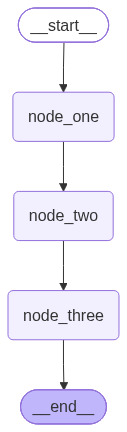

In [4]:
graph

In [8]:
initial_state = {
  "node1_done" : False,
  "node2_ done" : False,
  "node3_done" : False
}


#config banaune
thread_id = "user_1"

config = {
  "configurable" : {
    "thread_id" : thread_id
  }
}

response = graph.invoke(
  initial_state,
  config=config
)

print(response)

None1 Started...
Node1 Completed...
Node2 Started...


KeyboardInterrupt: 

In [ ]:
graph.invoke(
  None,
  config=config
)

#esari "None" value pathayesi jun Checkpoint ma Crash bhako thiyo tya bata Resume huncha

Node2 Started...
Node2 Completed...
Node3 Started...
Node3 Completed...


{'node1_done': True, 'node2_done': True, 'node3_done': True}